<img src="docs/images/appbakkers_logo.png" alt="AppBakkers" width="56" align="right">

# [Titel van het experiment]

*ECG/P-Cardio-onderzoek · experiment-template*

| | |
|---|---|
| **Auteur(s)** | [Naam, naam] |
| **Datum** | [JJJJ-MM-DD] |
| **Versie** | [0.1] |
| **Status** | [concept / in uitvoering / afgerond] |
| **Use case** | [UC-1 patiëntverificatie / UC-2 sensorartefactdetectie / UC-3 ritmeafwijkingen] |
| **Onderzoeksvraag** | [Vul hier de onderzoeksvraag in, als één vraag met een vraagteken.] |
| **Doel** | [Wat levert dit experiment op, en voor wie?] |

## Zo gebruik je dit template

Dit notebook is een leidraad voor hoe wij een experiment opzetten, uitvoeren en vastleggen. Elke sectie begint met
een korte instructie (*Wat schrijf je hier?*) en daarna een **uitgewerkt voorbeeld**. Het voorbeeld is een klein
UC-2-experiment op **synthetische data**, zodat alles direct werkt zonder echte ECG-gegevens.

1. Sla een kopie op in `experiments/<jouw-onderwerp>/` met een naam die zegt wat je onderzoekt, bijvoorbeeld
   `01_kwaliteit_tijdens_lopen.ipynb`.
2. Vul het titelblok in.
3. Vervang per sectie het voorbeeld door je eigen werk. Laat de koppen staan: dan vindt iedereen alles terug.
4. Draai het notebook aan het eind één keer helemaal opnieuw (*Restart & Run All*) voordat je het deelt.

> **Tip.** Schrijf voor een lezer die het project kent, maar jouw experiment niet. Zeg na elke grafiek of tabel
> in één of twee zinnen *wat je ziet*.

> **Let op.** ECG-gegevens zijn gezondheidsgegevens. Gebruik alleen deelnemer-ID's (`D002`), nooit namen, en
> commit geen echte opnames of uitvoer met herkenbare hartslagen zonder overleg.

## 0. Instellingen

Alle imports, de random seed en de opmaak staan bovenaan, in één cel. Zo zie je in één oogopslag waar het notebook
van afhangt, en geeft elke run dezelfde uitkomst.

De kleuren komen van de ECG-tool: **blauwgroen** voor gewone gegevens, **oranje** voor het
belangrijkste resultaat. Gebruik `stijl_tabel()` voor tabellen en `GRAFIEK` voor de kleuren in grafieken.

In [1]:
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from matplotlib import font_manager
from scipy import signal, stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

# --- reproduceerbaarheid: één seed voor alles wat toeval gebruikt ---
SEED = 42
rng = np.random.default_rng(SEED)

# --- huisstijl (gelijk aan de Streamlit ECG-tool) ---
PRIMAIR, DONKER, ORANJE = "#1E6F80", "#14525F", "#FF9806"
TEKST, SUBTIEL, RASTER, TINT = "#1F2A30", "#4A6A72", "#D6F0F6", "#E0F4F9"
GRAFIEK = [PRIMAIR, ORANJE, "#6EC6DA", DONKER, "#9FDCEB", "#8A4B00"]  # volgorde van het grafiekpalet

beschikbaar = {f.name for f in font_manager.fontManager.ttflist}
LETTERTYPE = next((f for f in ("DM Sans", "Segoe UI", "Arial") if f in beschikbaar), "DejaVu Sans")

plt.rcParams.update({
    "figure.figsize": (10, 3.6), "figure.dpi": 110, "font.family": LETTERTYPE, "font.size": 10,
    "axes.prop_cycle": matplotlib.cycler(color=GRAFIEK), "axes.edgecolor": RASTER, "axes.labelcolor": TEKST,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TEKST, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": RASTER, "grid.linewidth": 0.7, "xtick.color": SUBTIEL, "ytick.color": SUBTIEL,
    "legend.frameon": False, "lines.linewidth": 1.2,
})


def stijl_tabel(df: pd.DataFrame, decimalen: int = 2):
    """Rustige tabel in de huisstijl: lichte kop, dunne lijnen, getallen rechts uitgelijnd."""
    return (df.style.format(precision=decimalen, thousands=".", decimal=",")
            .set_table_styles([
                {"selector": "th", "props": f"background:{TINT}; color:{DONKER}; font-weight:600; text-align:left; padding:4px 10px;"},
                {"selector": "td", "props": f"border-bottom:1px solid {RASTER}; padding:4px 10px;"},
            ]))


print(f"Python {platform.python_version()} · numpy {np.__version__} · pandas {pd.__version__} · "
      f"matplotlib {matplotlib.__version__} · scipy {scipy.__version__} · scikit-learn {sklearn.__version__}")
print(f"Lettertype grafieken: {LETTERTYPE}")

Python 3.12.3 · numpy 2.5.3 · pandas 2.3.3 · matplotlib 3.11.2 · scipy 1.18.1 · scikit-learn 1.9.1
Lettertype grafieken: DejaVu Sans


> **Tip.** Noteer de versies (de regel hierboven) in je verslag. Een ander resultaat bij een collega komt vaak
> door een andere versie van een package.

## 1. Onderzoeksvraag en hypothese

*Wat schrijf je hier?* Eén onderzoeksvraag, zo concreet dat het antwoord ja/nee of een getal is. Daarna de
hypothese: wat verwacht je, en wanneer noem je die bevestigd? Spreek dat **vóór** het experiment af.

**Voorbeeld**

**Onderzoeksvraag:** Is de signaalkwaliteit van een ECG-venster van 10 s lager tijdens beweging dan in rust?

| | Uitspraak |
|---|---|
| **H₀** (nulhypothese) | De kwaliteitsmaat verschilt niet tussen rust en beweging. |
| **H₁** (verwachting) | De kwaliteitsmaat is lager tijdens beweging. |
| **Beslisregel** | We verwerpen H₀ als de Mann-Whitney-U-toets *p* < 0,05 geeft. |

## 2. Achtergrond en context

*Wat schrijf je hier?* Waarom doe je dit experiment, bij welke use case hoort het, en wat weten we al? Verwijs naar
eerdere notebooks of literatuur. Kort: een paar alinea's.

**Voorbeeld**

Dit experiment hoort bij **UC-2: sensorartefactdetectie**. Thuis bewegen mensen; daardoor ontstaan *artefacten*:
verstoringen in het signaal die niet van het hart komen. Om die automatisch te herkennen, hebben we een maat nodig
die zegt hoe "schoon" een stuk ECG is.

Een schoon ECG is *piekerig*: smalle R-toppen, daartussen bijna vlak. Dat meet de **kurtosis** $\kappa$ van een
signaal $x$ met gemiddelde $\mu$ en standaardafwijking $\sigma$:

$$\kappa = \frac{1}{n} \sum_{i=1}^{n} \left( \frac{x_i - \mu}{\sigma} \right)^4$$

Een schoon ECG heeft een kurtosis boven ongeveer 5; ruis door beweging verlaagt die (Li, Mark & Clifford, 2008).
Eerder werk in dit project: `experiments/ecg_id/09_signaalkwaliteit_beweging.ipynb`.

## 3. Dataset en benodigdheden

*Wat schrijf je hier?* Welke data, van welk apparaat, hoeveel, en wat heb je verder nodig? Een tabel werkt goed.

**Voorbeeld**

| Onderdeel | Keuze |
|---|---|
| Databron | Synthetisch ECG, met dezelfde opbouw als een CSV-export van de P-Cardio (`Ecg_2Ch.csv`) |
| Sensor | ECG-kanaal 1 (afleiding I), 250 Hz |
| Omvang | 60 vensters van 10 s in rust, 60 met bewegingsruis |
| Packages | numpy, pandas, scipy, matplotlib, scikit-learn (zie de versies in sectie 0) |
| Randvoorwaarde | Geen echte deelnemerdata nodig; draait in een paar seconden |

> **Let op.** Werk je met echte opnames, noteer dan per bestand: deelnemer-ID, datum, plaatsing (sticker of
> lanyard) en de meetconfiguratie. Die staan in de ECG-tool bij de opname.

## 4. Onderzoeksmethode

*Wat schrijf je hier?* De aanpak in stappen, de variabelen, hoe je meet en hoe je beoordeelt of het gelukt is.

**Voorbeeld**

1. Maak 120 vensters synthetisch ECG; voeg bij de helft bewegingsruis toe.
2. Filter elk venster (banddoorlaat 0,5–40 Hz) en bereken de kurtosis.
3. Vergelijk rust en beweging met een Mann-Whitney-U-toets (geen aanname van normaliteit).
4. Kijk of een eenvoudige classifier met alleen de kurtosis de twee groepen uit elkaar houdt.

| Variabele | Rol | Waarden |
|---|---|---|
| Activiteit | onafhankelijk | rust, beweging |
| Kurtosis | afhankelijk | getal, hoger = schoner |
| Hartslag, ruisniveau | vast gehouden | 70 bpm, ruis 0,02 mV |

**Evaluatiecriteria:** *p*-waarde van de toets; nauwkeurigheid van de classifier op een **aparte testset**
(nooit op de data waarmee getraind is).

## 5. Datavoorbereiding

*Wat doe je hier?* Data inladen, controleren en voorbereiden. Laat elke controle zien, ook als er niets mis is:
dan weet de lezer dat je het gecontroleerd hebt.

### 5.1 Synthetische data maken

In een echt experiment sla je deze stap over. Hier maken we een signaal dat op een ECG lijkt: per hartslag een paar
golfjes (P, QRS, T) als gaussische pieken.

In [2]:
FS = 250  # samplefrequentie (Hz), zoals de P-Cardio
VENSTER_S = 10


def synthetisch_ecg(n_samples: int, fs: int = FS, hartslag: float = 70.0) -> np.ndarray:
    """PQRST-achtig signaal in mV: per hartslag een som van gaussische golfjes, plus lichte ruis."""
    t = np.arange(n_samples) / fs
    fase = np.mod(t, 60 / hartslag) / (60 / hartslag)
    golven = [(0.12, 0.16, 0.025), (-0.12, 0.26, 0.008), (1.1, 0.28, 0.01), (-0.25, 0.30, 0.008), (0.3, 0.55, 0.04)]
    ecg = sum(a * np.exp(-((fase - mu) ** 2) / (2 * s**2)) for a, mu, s in golven)
    return ecg + rng.normal(0, 0.02, n_samples)


def bewegingsruis(n_samples: int, fs: int = FS) -> np.ndarray:
    """Trage golf (ademhaling, schuiven) plus korte, grote uitslagen (stappen, tikken tegen de kabel)."""
    t = np.arange(n_samples) / fs
    traag = 0.4 * np.sin(2 * np.pi * rng.uniform(0.2, 0.6) * t)
    stoten = np.convolve(rng.normal(0, 1, n_samples) * (rng.random(n_samples) < 0.01), np.hanning(40), "same")
    return traag + 0.5 * stoten


# Eén doorlopende "opname" met de opbouw van een P-Cardio-CSV-export: datum, tijd, kanaal in mV.
n = VENSTER_S * FS
vensters = [(synthetisch_ecg(n) + (bewegingsruis(n) if i % 2 else 0), "beweging" if i % 2 else "rust")
            for i in range(120)]
start = pd.Timestamp("2026-10-19 10:00:00")
opname = pd.DataFrame({
    "Date": start.strftime("%Y/%m/%d"),
    "Time (UTC+01:00)": (start + pd.to_timedelta(np.arange(120 * n) / FS, unit="s")).strftime("%H:%M:%S.%f"),
    "Ecg1 (mV)": np.concatenate([v for v, _ in vensters]),
})
activiteit = np.repeat([a for _, a in vensters], n)

# Een paar fouten erin, zodat de controles hieronder iets te vinden hebben.
opname.loc[rng.choice(len(opname), 25, replace=False), "Ecg1 (mV)"] = np.nan  # ontbrekende samples
opname.loc[rng.choice(len(opname), 5, replace=False), "Ecg1 (mV)"] = 999.0    # onmogelijke waarden
opname.to_csv("voorbeeld_Ecg_2Ch.csv", index=False)
print(f"{len(opname):,} samples weggeschreven naar voorbeeld_Ecg_2Ch.csv".replace(",", "."))

300.000 samples weggeschreven naar voorbeeld_Ecg_2Ch.csv


### 5.2 Inladen met pandas

`pd.read_csv` leest een CSV-export van de P-Cardio. Zet datum en tijd om naar één tijdkolom: daarmee kun je later
koppelen aan annotaties.

In [3]:
df = pd.read_csv("voorbeeld_Ecg_2Ch.csv")
# Echte export: pd.read_csv("experiments/<onderwerp>/data/Ecg_2Ch.csv") — zelfde kolommen.
df["tijd"] = pd.to_datetime(df["Date"] + " " + df["Time (UTC+01:00)"], format="%Y/%m/%d %H:%M:%S.%f")
df = df.rename(columns={"Ecg1 (mV)": "ecg_mv"})[["tijd", "ecg_mv"]]
df.head()

,tijd,ecg_mv
0,2026-10-19 10:00:00.000,0.006094
1,2026-10-19 10:00:00.004,-0.020800
2,2026-10-19 10:00:00.008,0.015009
3,2026-10-19 10:00:00.012,0.018811
4,2026-10-19 10:00:00.016,-0.039021


### 5.3 Controleren

Vier vragen die je bij elke dataset stelt: klopt de samplefrequentie, ontbreekt er iets, zijn er onmogelijke
waarden, en lopen de tijden netjes op?

In [4]:
stappen = df["tijd"].diff().dt.total_seconds().dropna()
controles = pd.DataFrame({
    "controle": ["samplefrequentie (Hz)", "ontbrekende waarden", "onmogelijke waarden (|x| > 5 mV)",
                 "tijden niet oplopend"],
    "uitkomst": [round(1 / stappen.median()), df["ecg_mv"].isna().sum(), (df["ecg_mv"].abs() > 5).sum(),
                 (stappen <= 0).sum()],
    "verwacht": [FS, 0, 0, 0],
})
stijl_tabel(controles, decimalen=0).hide(axis="index")

controle,uitkomst,verwacht
samplefrequentie (Hz),250,250
ontbrekende waarden,25,0
onmogelijke waarden (|x| > 5 mV),5,0
tijden niet oplopend,0,0


**Wat je ziet:** de samplefrequentie klopt, maar er ontbreken 25 samples en 5 waarden van 999 mV kunnen niet
(een hartsignaal is ongeveer 1 mV). Die maken we hieronder leeg en vullen we op.

### 5.4 Opschonen en filteren

Onmogelijke waarden worden `NaN`, gaten vullen we lineair op (het zijn losse samples). Daarna een banddoorlaatfilter
van 0,5–40 Hz: dat haalt de trage drift en hoogfrequente ruis weg. `sosfiltfilt` filtert vooruit en achteruit, zodat
de pieken niet verschuiven.

In [5]:
df.loc[df["ecg_mv"].abs() > 5, "ecg_mv"] = np.nan
df["ecg_mv"] = df["ecg_mv"].interpolate(limit=5)
assert df["ecg_mv"].notna().all(), "Er zijn nog gaten van meer dan 5 samples."

sos = signal.butter(3, [0.5, 40], btype="bandpass", fs=FS, output="sos")
df["ecg_gefilterd"] = signal.sosfiltfilt(sos, df["ecg_mv"])
df["activiteit"] = activiteit
print("Opgeschoond en gefilterd; geen ontbrekende waarden meer.")

Opgeschoond en gefilterd; geen ontbrekende waarden meer.


> **Tip.** Een `assert` stopt het notebook met een duidelijke melding als een aanname niet klopt. Beter een fout
> hier dan een verkeerd resultaat drie secties verder.

## 6. Uitvoering van het experiment

*Wat doe je hier?* De berekeningen, analyses of modeltraining. Houd elke cel klein en zet er één zin uitleg boven.

### 6.1 Kurtosis per venster

In [6]:
df["venster"] = np.arange(len(df)) // n
per_venster = df.groupby("venster").agg(
    activiteit=("activiteit", "first"),
    kurtosis=("ecg_gefilterd", lambda x: stats.kurtosis(x, fisher=False)),
    std_mv=("ecg_gefilterd", "std"),
)
stijl_tabel(per_venster.groupby("activiteit").agg(vensters=("kurtosis", "size"), kurtosis_mediaan=("kurtosis", "median"),
                                                   std_mediaan_mv=("std_mv", "median")))

,vensters,kurtosis_mediaan,std_mediaan_mv
activiteit,,,
beweging,60,"8,39","0,24"
rust,60,"21,02","0,15"


### 6.2 Toets: verschilt de kurtosis tussen rust en beweging?

In [7]:
rust = per_venster.loc[per_venster["activiteit"] == "rust", "kurtosis"]
beweging = per_venster.loc[per_venster["activiteit"] == "beweging", "kurtosis"]
toets = stats.mannwhitneyu(rust, beweging, alternative="greater")
print(f"Mann-Whitney U = {toets.statistic:.0f}, p = {toets.pvalue:.2g}")

Mann-Whitney U = 3600, p = 1.8e-21


### 6.3 Classifier: herkent alleen de kurtosis een bewegingsvenster?

Altijd splitsen in een **trainset** en een **testset**, en de score alleen op de testset rapporteren. Met
`stratify` zitten in beide sets evenveel rust- als bewegingsvensters; `random_state=SEED` maakt de splitsing
reproduceerbaar.

In [8]:
X = per_venster[["kurtosis"]].to_numpy()
y = (per_venster["activiteit"] == "beweging").to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)

model = LogisticRegression().fit(X_train, y_train)
voorspeld = model.predict(X_test)
print(f"Nauwkeurigheid op de testset: {accuracy_score(y_test, voorspeld):.0%} ({len(y_test)} vensters)")

Nauwkeurigheid op de testset: 97% (36 vensters)


## 7. Resultaten en visualisaties

*Wat doe je hier?* De resultaten overzichtelijk tonen. Elke grafiek heeft een titel die het **resultaat** zegt,
aslabels **met eenheid**, en een legenda als er meer dan één lijn of groep is. Zet het belangrijkste in oranje, de
rest in blauwgroen.

### 7.1 Een venster in rust en een met beweging

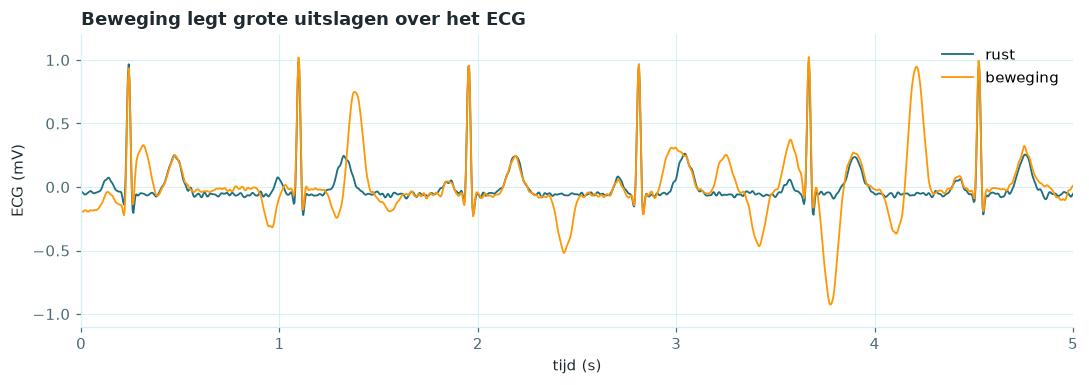

In [9]:
fig, ax = plt.subplots()
t = np.arange(n) / FS
for naam, kleur in [("rust", PRIMAIR), ("beweging", ORANJE)]:
    eerste = df.loc[df["activiteit"] == naam, "venster"].iloc[0]
    ax.plot(t, df.loc[df["venster"] == eerste, "ecg_gefilterd"], color=kleur, label=naam)
ax.set(title="Beweging legt grote uitslagen over het ECG",
       xlabel="tijd (s)", ylabel="ECG (mV)", xlim=(0, 5))
ax.legend(loc="upper right")
fig.tight_layout()

**Wat je ziet:** in rust (blauwgroen) zie je alleen de hartslagen; met beweging (oranje) komen er grote uitslagen
bij, waarvan sommige op een hartslag lijken. Precies dat maakt artefacten lastig.

### 7.2 De kurtosis per groep

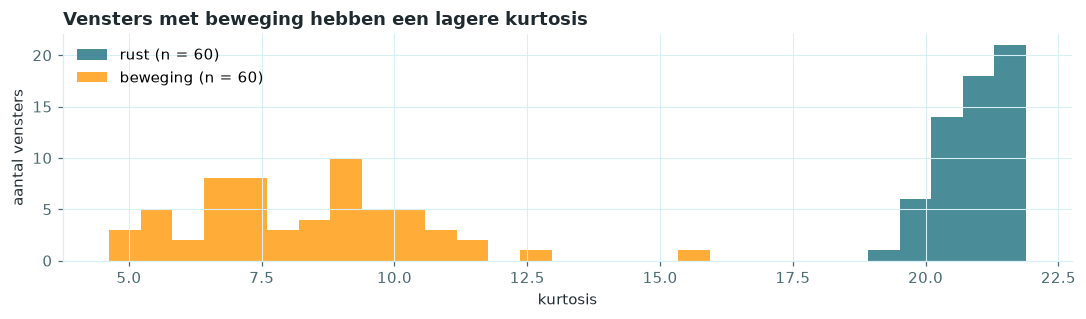

In [10]:
fig, ax = plt.subplots(figsize=(10, 3))
bakken = np.linspace(per_venster["kurtosis"].min(), per_venster["kurtosis"].max(), 30)
ax.hist(rust, bins=bakken, color=PRIMAIR, alpha=0.8, label=f"rust (n = {len(rust)})")
ax.hist(beweging, bins=bakken, color=ORANJE, alpha=0.8, label=f"beweging (n = {len(beweging)})")
ax.set(title="Vensters met beweging hebben een lagere kurtosis", xlabel="kurtosis", ylabel="aantal vensters")
ax.legend()
fig.tight_layout()

### 7.3 Verwarringsmatrix van de classifier

Rijen zijn de echte klasse, kolommen de voorspelling. Op de diagonaal staat wat goed is.

In [11]:
matrix = pd.DataFrame(confusion_matrix(y_test, voorspeld), index=["echt: rust", "echt: beweging"],
                      columns=["voorspeld: rust", "voorspeld: beweging"])
stijl_tabel(matrix, decimalen=0)

,voorspeld: rust,voorspeld: beweging
echt: rust,18,0
echt: beweging,1,17


## 8. Evaluatie en discussie

*Wat schrijf je hier?* Wat betekenen de resultaten, klopt de hypothese, en wat zijn de beperkingen? Wees eerlijk:
een duidelijke beperking is waardevoller dan een te mooi resultaat.

**Voorbeeld**

- **Hypothese:** bevestigd. De kurtosis is in rust duidelijk hoger dan met beweging (*p* ver onder 0,05; zie 6.2),
  en een classifier met alleen de kurtosis herkent de testvensters vrijwel allemaal.
- **Beperkingen:**
  - De data is **synthetisch**: echte bewegingsruis is wisselender, en een echte opname bevat ook stukken met maar
    een beetje beweging.
  - Eén hartslag (70 bpm) en één ruisniveau; bij een hogere hartslag verandert de kurtosis ook.
  - Rust en beweging wisselen elkaar strikt af; echte opnames hebben overgangen.
- **Wat dit níét laat zien:** of de maat ook werkt op de P-Cardio, aan de lanyard, of bij zweet en losse elektroden.

## 9. Conclusie en vervolgonderzoek

*Wat schrijf je hier?* Het antwoord op de onderzoeksvraag in één of twee zinnen, en de volgende stappen.

**Voorbeeld**

**Antwoord:** ja, op synthetische data is de signaalkwaliteit (kurtosis) duidelijk lager tijdens beweging.

**Vervolg:**
1. Dezelfde analyse op echte P-Cardio-opnames met geannoteerde activiteiten (ECG-tool, pagina *Export*).
2. Meer kwaliteitsmaten vergelijken (zie `09_signaalkwaliteit_beweging.ipynb`).
3. Het effect van de hartslag scheiden van het effect van beweging.

---

## Naslag

### Markdown in een notebook

| Wat | Zo schrijf je het | Resultaat |
|---|---|---|
| Vet, cursief | `**vet**`, `*cursief*` | **vet**, *cursief* |
| Code in een zin | `` `df.head()` `` | `df.head()` |
| Link | `[pandas](https://pandas.pydata.org)` | [pandas](https://pandas.pydata.org) |
| Formule in een zin | `$\sqrt{k}$` | $\sqrt{k}$ |
| Formule apart | `$$ ... $$` | zie sectie 2 |
| Kop | `## Kop` | een sectiekop |

Lijsten: begin een regel met `-` (opsomming) of `1.` (genummerd). Tabellen: kolommen scheiden met `|`, onder de kop
een regel `|---|---|`.

**Meldingen** schrijf je als citaat, zodat ze in Jupyter én VS Code goed staan:

```
> **Tip.** Een handige aanwijzing.
> **Let op.** Iets dat fout kan gaan.
```

### Officiële documentatie

| Package | Waarvoor | Documentatie |
|---|---|---|
| Python | de taal zelf | <https://docs.python.org/3/> |
| NumPy | rekenen met arrays | <https://numpy.org/doc/stable/> |
| pandas | tabellen inlezen en bewerken | <https://pandas.pydata.org/docs/> |
| matplotlib | grafieken | <https://matplotlib.org/stable/> |
| SciPy | filters (`scipy.signal`), statistiek (`scipy.stats`) | <https://docs.scipy.org/doc/scipy/> |
| scikit-learn | modellen en evaluatie | <https://scikit-learn.org/stable/> |

### Checklist voordat je deelt

- [ ] Titelblok ingevuld, status bijgewerkt.
- [ ] *Restart & Run All* zonder fouten.
- [ ] Bij elke grafiek en tabel een zin over wat je ziet.
- [ ] Geen namen of herkenbare deelnemerdata in de uitvoer.
- [ ] Voorbeeldbestanden (`voorbeeld_Ecg_2Ch.csv`) verwijderd als je ze niet meer nodig hebt.